# Bildung in Deutschland 2006 bis 2026: Herausforderungen und Indikatoren

## Worum es geht

Dieses Notebook beantwortet den zweiten Teil von Forschungsfrage 2: Wie entwickeln sich die Indikatoren zu den Herausforderungen, die der Bericht wiederholt benennt?

`03_bewertung_handlungsbedarf.ipynb` hat neun wiederkehrende Herausforderungen gefunden und in drei Stufen eingeteilt. Bisher beruhen alle Befunde auf dem Fließtext. Hier kommen die Tabellen der Berichte hinzu. Der Abgleich hat drei Teile:

1. **Abdeckung:** Zu welchen Herausforderungen enthält der Bericht Tabellen, und wie viele in jedem Jahr?
2. **Text und Tabellen:** Wächst die Zahl der Tabellen zu einer Herausforderung, wenn der Text mehr Handlungsbedarf benennt?
3. **Leitindikatoren:** Wie entwickelt sich je Herausforderung eine zentrale Kennzahl über die Zeit?

## Inhalt dieses Notebooks

| Teil | Abschnitte | Frage |
|---|---|---|
| Daten | 1 bis 2: Grundlagen, Bestand laden | Welche Tabellen gibt es in welchem Bericht? |
| Zuordnung | 3: Tabellen den Herausforderungen zuordnen | Welche Tabelle gehört zu welcher Herausforderung? |
| Abdeckung | 4: Abbildung 14 | Wie viele Tabellen gibt es je Herausforderung und Jahr? |
| Text und Tabellen | 5: Abbildung 15 | Folgen die Tabellen dem Handlungsbedarf im Text? |
| Leitindikatoren | 6: Abbildung 16 | Wie entwickelt sich je Herausforderung eine zentrale Kennzahl? |

Die Abbildungen setzen die Nummerierung aus `04_tabellenbestand.ipynb` fort.

## Datengrundlage

Dieses Notebook arbeitet mit dem bereinigten Bestand aus `04_tabellenbestand.ipynb`: ohne Kopien, Fortsetzungen, fremde Blätter und Abbildungen. Es zählt nur Tabellen. Die Daten zu Abbildungen gibt es nicht für alle Jahre im gleichen Umfang, 2020 fast für alle Abbildungen des Buchs, sonst nur für wenige. Mit ihnen wären die Jahre nicht vergleichbar.

Das Notebook gibt keine Tabellentitel und keine Tabelleninhalte aus. Es zeigt nur Tabellennummern, Zählungen und einzelne Kennzahlen mit Quellenangabe. Die Titel zur Kontrolle schreibt es in Dateien unter `data/interim`. Dieser Ordner steht in der `.gitignore`.

## Voraussetzungen

- `03_bewertung_handlungsbedarf.ipynb` ist gelaufen und hat `data/processed/handlungsbedarf_themen_jahr.csv` erzeugt.
- `04_tabellenbestand.ipynb` ist gelaufen und hat `data/interim/tabellenbestand.rds` erzeugt.
- R 4.6.1 mit den Paketen `dplyr`, `tidyr`, `ggplot2`, `stringr`, `purrr`, `readxl` und `writexl`. Die erste Zelle installiert fehlende Pakete.

## Laufzeit

Wenige Minuten. Abschnitt 6 liest die passenden Tabellen des Berichts 2026 vollständig.

### 1. Grundlagen

Die erste Zelle lädt die Pakete, legt die neun Herausforderungen aus `03_bewertung_handlungsbedarf.ipynb` fest und liest die Zahl der Sätze mit Handlungsbedarf je Thema und Jahr.

| Thema | Herausforderung | Stufe aus Notebook 03 |
|---|---|---|
| T5 | Steuerung des Bildungssystems | belastbar |
| T12 | Demografischer und wirtschaftlicher Wandel | belastbar |
| T11 | Pädagogisches Personal | belastbar |
| T38 | Soziale Herkunft und Ungleichheit | belastbar |
| T29 | Lehrkräfte | belastbar |
| T30 | Kindertagesbetreuung | mit Einschränkung |
| T33 | Programme und Qualitätssicherung | modellabhängig |
| T18 | Ausbildungsmarkt und Übergangssystem | modellabhängig |
| T3 | Frühe Bildung allgemein | modellabhängig |

Die drei modellabhängigen Herausforderungen laufen als Ergänzung mit. Ihre Ergebnisse stehen in den Abbildungen getrennt und gelten nur unter Vorbehalt.

In [8]:
setwd("C:/Users/c.sezgin/OneDrive - DIPF/Computational Social Sciences/bildungsbericht")
.libPaths(c(Sys.getenv("R_LIBS_USER"), .libPaths()))
pakete <- c("dplyr", "tidyr", "ggplot2", "stringr", "purrr", "readxl", "writexl")
for (paket in pakete) {
  if (!requireNamespace(paket, quietly = TRUE)) install.packages(paket)
}
suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(stringr)
  library(purrr)
})
dir.create("figures", showWarnings = FALSE)

jahre <- seq(2006, 2026, by = 2)
quelle <- "Quelle: Bildung in Deutschland 2006 bis 2026, Tabellen und Text der Berichte, eigene Berechnung"

herausforderungen <- tribble(
  ~thema, ~kurz,                         ~stufe,
  5,      "Steuerung",                   "belastbar",
  12,     "Demografischer Wandel",       "belastbar",
  11,     "Pädagogisches Personal",      "belastbar",
  38,     "Soziale Herkunft",            "belastbar",
  29,     "Lehrkräfte",                  "belastbar",
  30,     "Kindertagesbetreuung",        "mit Einschränkung",
  33,     "Programme und QS",            "modellabhängig",
  18,     "Ausbildungsmarkt",            "modellabhängig",
  3,      "Frühe Bildung",               "modellabhängig"
) |>
  mutate(stufe = factor(stufe, levels = c("belastbar", "mit Einschränkung", "modellabhängig")),
         kurz = factor(kurz, levels = kurz))

h_jahr <- read.csv("data/processed/handlungsbedarf_themen_jahr.csv", fileEncoding = "UTF-8")
stopifnot("Ein Thema fehlt in handlungsbedarf_themen_jahr.csv." =
            all(herausforderungen$thema %in% h_jahr$thema))
cat("Themen in der Datei aus Notebook 03:", n_distinct(h_jahr$thema), "\n")
cat("Jahre:", paste(sort(unique(h_jahr$jahr)), collapse = ", "), "\n")
cat("Sätze mit Handlungsbedarf, alle inhaltlichen Themen:", sum(h_jahr$handlungsbedarf), "\n")

Themen in der Datei aus Notebook 03: 32 
Jahre: 2006, 2008, 2010, 2012, 2014, 2016, 2018, 2020, 2022, 2024, 2026 
Sätze mit Handlungsbedarf, alle inhaltlichen Themen: 2193 


### 2. Bestand laden

Die Zelle liest den bereinigten Bestand aus `04_tabellenbestand.ipynb` und behält nur die Tabellen. Jede Tabelle hat ihre Kapitelgruppe wie in den Notebooks 02 und 03: Tabellen aus Kapitel H gehören zum Schwerpunktkapitel, alle anderen zu den Kernkapiteln. Überblick und Einleitung haben keine Tabellen.

In [9]:
tabellen <- readRDS("data/interim/tabellenbestand.rds") |>
  filter(art == "Tabelle")

cat("Tabellen im Bestand:", nrow(tabellen), "\n")
cat("Ohne Titel:", sum(is.na(tabellen$titel)), "\n\n")
cat("Tabellen je Bericht und Kapitelgruppe:\n")
print(table(tabellen$jahr, tabellen$kapitelgruppe))

Tabellen im Bestand: 4397 
Ohne Titel: 2 

Tabellen je Bericht und Kapitelgruppe:
      
       Kernkapitel Schwerpunkt H
  2006         188            31
  2008         259            36
  2010         329            47
  2012         368            87
  2014         375            81
  2016         324            76
  2018         390            31
  2020         323            76
  2022         332            49
  2024         446            22
  2026         512            15


**Befund zu Abschnitt 2:** Der Bestand enthält 4.397 Tabellen, nur 2 ohne Titel. In den Kernkapiteln wächst die Zahl von 188 (2006) auf 512 (2026). Das Schwerpunktkapitel H hat zwischen 15 (2026) und 87 Tabellen (2012).

### 3. Tabellen den Herausforderungen zuordnen

Ich ordne jede Tabelle über ihren Titel zu. Für jede Herausforderung lege ich eine Liste von Wortteilen fest. Enthält der klein geschriebene Titel einen davon, gehört die Tabelle zur Herausforderung. Eine Tabelle kann zu mehreren Herausforderungen gehören, etwa eine Tabelle zum Personal in Kindertageseinrichtungen zu pädagogischem Personal und zu Kindertagesbetreuung.

Die Wortteile treffen auch zusammengesetzte Wörter: "kindertage" trifft "Kindertageseinrichtungen" und "Kindertagespflege". Das Verfahren ist einfach und für jede Tabelle überprüfbar. Seine Schwäche gleicht der des Wörterbuchs in Notebook 03: Es erkennt keine Bedeutung. "personal" trifft auch "Personalausgaben".

Nach dem ersten Lauf habe ich die Treffer geprüft und drei Wortteile ersetzt, weil sie vor allem fremde Tabellen trafen:

- "sozial" traf auch "sozialversicherungspflichtig", "Freiwilliges Soziales Jahr" und den Ausbildungsgang Sozialassistenz. Ich suche jetzt nur nach Wendungen wie "soziale Herkunft", "sozialer Gradient" oder "soziale Disparitäten".
- "herkunft" traf vor allem Herkunftsstaaten und Herkunftsregionen, also Migration. Ich behalte nur "Bildungsherkunft" und "soziale Herkunft".
- "wanderung" traf vor allem "Einwanderungsgeschichte", also ebenfalls Migration. Ich behalte nur Wanderungssaldo und Binnenwanderung.

Alle neuen Wortteile sind Teil der alten. Die Liste trifft also weniger Tabellen, aber genauere.

Steuerung hat keine eindeutige Kennzahl. Die Liste sucht nach Tabellen zu Steuerung, Monitoring, Aufsicht und Eigenverantwortung von Einrichtungen. Wenige Treffer sind hier ein Ergebnis und kein Fehler.

Alle Treffer mit Titel schreibe ich nach `data/interim/tabellen_herausforderungen.xlsx`. Dort lässt sich prüfen, ob die Zuordnung stimmt. Wörter, die oft falsch treffen, kann man aus der Liste nehmen und die Zelle neu ausführen.

In [10]:
schluessel <- tribble(
  ~thema, ~muster,
  5,  "steuerung|governance|bildungsmonitoring|schulaufsicht|schulinspektion|eigenverantwort|autonomie",
  12, "demograf|bevölkerungsentwicklung|bevölkerungsvorausberechnung|bevölkerungsstruktur|altersstruktur|geburt|wanderungssaldo|binnenwanderung|bruttoinlandsprodukt",
  11, "personal|fachkräfte|pädagogisch tätig|tätige person|erzieher",
  38, "soziale[nr]? herkunft|bildungsherkunft|sozialer? gradient|sozialen? disparität|sozialstruktur|soziale[nr]? merkmal|sozialem status|sozialstatus|sozialer stellung|soziale mobilität|sozialschicht|sozioökonom|hisei|bildungsstand der eltern|elterlich|risikolage|armut|sozialgeld|sozialhilfe|benachteilig",
  29, "lehrkräfte|lehrer|lehramt|referendar|vorbereitungsdienst|seiteneinst|quereinst",
  30, "kindertage|tageseinrichtung|tagespflege|kita|krippe|kindergarten|betreuungsquote|betreuungsbedarf|betreuungsumfang",
  33, "qualitätssicherung|qualitätsentwicklung|evaluation|vergleichsarbeit|lernstand|bildungsstandard|programm|akkreditier",
  18, "ausbildungsstelle|ausbildungsvertr|ausbildungsplatz|ausbildungsmarkt|übergangssystem|übergangssektor|übergangsbereich|bewerber|einmündung|duale ausbildung|duales system",
  3,  "frühe bildung|frühkindlich|vorschul|sprachstand|sprachförder|einschulung|unter 3|unter drei|vor dem schuleintritt"
) |>
  left_join(herausforderungen, by = "thema")

titel_klein <- tolower(coalesce(tabellen$titel, ""))
treffer <- map_dfr(seq_len(nrow(schluessel)), function(i) {
  passt <- grepl(schluessel$muster[i], titel_klein, perl = TRUE)
  tabellen[passt, ] |>
    mutate(thema = schluessel$thema[i], kurz = schluessel$kurz[i], stufe = schluessel$stufe[i],
           wort = str_match(titel_klein[passt], schluessel$muster[i])[, 1])
})

writexl::write_xlsx(treffer |> select(kurz, jahr, tab_nr, wort, titel) |> arrange(kurz, jahr, tab_nr),
                    "data/interim/tabellen_herausforderungen.xlsx")

cat("Zugeordnete Tabellen (mit Mehrfachzuordnung):", nrow(treffer), "\n")
cat("Tabellen mit mindestens einer Herausforderung:", n_distinct(treffer$pfad, treffer$blatt),
    "von", nrow(tabellen), "\n\n")
cat("Treffer je Herausforderung und auslösendem Wortteil (häufigste 5):\n")
treffer |>
  count(kurz, wort, sort = TRUE) |>
  group_by(kurz) |>
  slice_head(n = 5) |>
  ungroup() |>
  arrange(kurz, desc(n)) |>
  print(n = Inf)

Zugeordnete Tabellen (mit Mehrfachzuordnung): 1552 
Tabellen mit mindestens einer Herausforderung: 1371 von 4397 

Treffer je Herausforderung und auslösendem Wortteil (häufigste 5):
# A tibble: 38 × 3
   kurz                   wort                         n
   <fct>                  <chr>                    <int>
 1 Demografischer Wandel  bruttoinlandsprodukt        42
 2 Demografischer Wandel  geburt                      38
 3 Demografischer Wandel  demograf                    36
 4 Demografischer Wandel  wanderungssaldo              3
 5 Demografischer Wandel  altersstruktur               1
 6 Pädagogisches Personal personal                   293
 7 Pädagogisches Personal erzieher                    19
 8 Pädagogisches Personal pädagogisch tätig           15
 9 Pädagogisches Personal fachkräfte                   7
10 Pädagogisches Personal tätige person                1
11 Soziale Herkunft       risikolage                  43
12 Soziale Herkunft       sozioökonom                 42
1

**Befund zu Abschnitt 3:** Die Wortlisten ordnen 1.371 der 4.397 Tabellen (31 Prozent) mindestens einer Herausforderung zu, mit Mehrfachzuordnung 1.552 Treffer.

- **Soziale Herkunft** stützt sich auf Risikolagen (43 Treffer), sozioökonomischen Status (42), soziale Herkunft (16), Bildungsherkunft (12) und Bildungsstand der Eltern (10).
- **Demografischer Wandel** stützt sich auf Bruttoinlandsprodukt (42), Geburten und Geburtskohorten (38) und Demografie (36). Das Bruttoinlandsprodukt gehört zum wirtschaftlichen Teil des Themas.
- **Pädagogisches Personal** bleibt breit: "personal" trifft 293 Tabellen, darunter auch Hochschulpersonal und Personalschlüssel. Die Zählung ist hier eher zu hoch.
- **Steuerung** trifft keine einzige Tabelle. **Programme und Qualitätssicherung** trifft 28 Tabellen, fast alle über "programm" und "bildungsstandard".

### 4. Abdeckung: Tabellen je Herausforderung und Bericht

Die Berichte enthalten über die Jahre unterschiedlich viele Tabellen. Ich zeige deshalb neben der Zahl der Tabellen auch ihren Anteil an allen Tabellen des Berichts. Ein steigender Anteil heißt: Der Bericht widmet der Herausforderung einen größeren Teil seiner Tabellen.

Die Zelle speichert die Zählungen ohne Titel unter `data/processed/indikatoren_abdeckung.csv`.

#### Abbildung 14: Tabellen je Herausforderung und Bericht

Jede Zeile ist eine Herausforderung, jede Spalte ein Bericht. Die Farbe zeigt den Anteil an allen Tabellen des Berichts, die Zahl im Feld die Zahl der Tabellen. Das linke Feld zählt alle Kapitel, das rechte nur die Kernkapitel. Ein leeres Feld heißt: In diesem Bericht gibt es keine passende Tabelle.

Tabellen je Herausforderung, alle Kapitel:
# A tibble: 9 × 12
  kurz                   `2006` `2008` `2010` `2012` `2014` `2016` `2018` `2020`
  <fct>                   <int>  <int>  <int>  <int>  <int>  <int>  <int>  <int>
1 Steuerung                   0      0      0      0      0      0      0      0
2 Demografischer Wandel       9      6     10     11      8      8      8     19
3 Pädagogisches Personal      7     22     26     28     35     40     42     30
4 Soziale Herkunft            4      8     14     22     21     20     13     11
5 Lehrkräfte                  0     12     13     11     12      7      3     18
6 Kindertagesbetreuung       24     30     33     41     40     55     45     32
7 Programme und QS            0      0      0     14      3      1      2      0
8 Ausbildungsmarkt            7      8      7      9      9      7     16     11
9 Frühe Bildung              10     13     16     19     26     33     23     17
  `2022` `2024` `2026`
   <int>  <int>  <int>
1

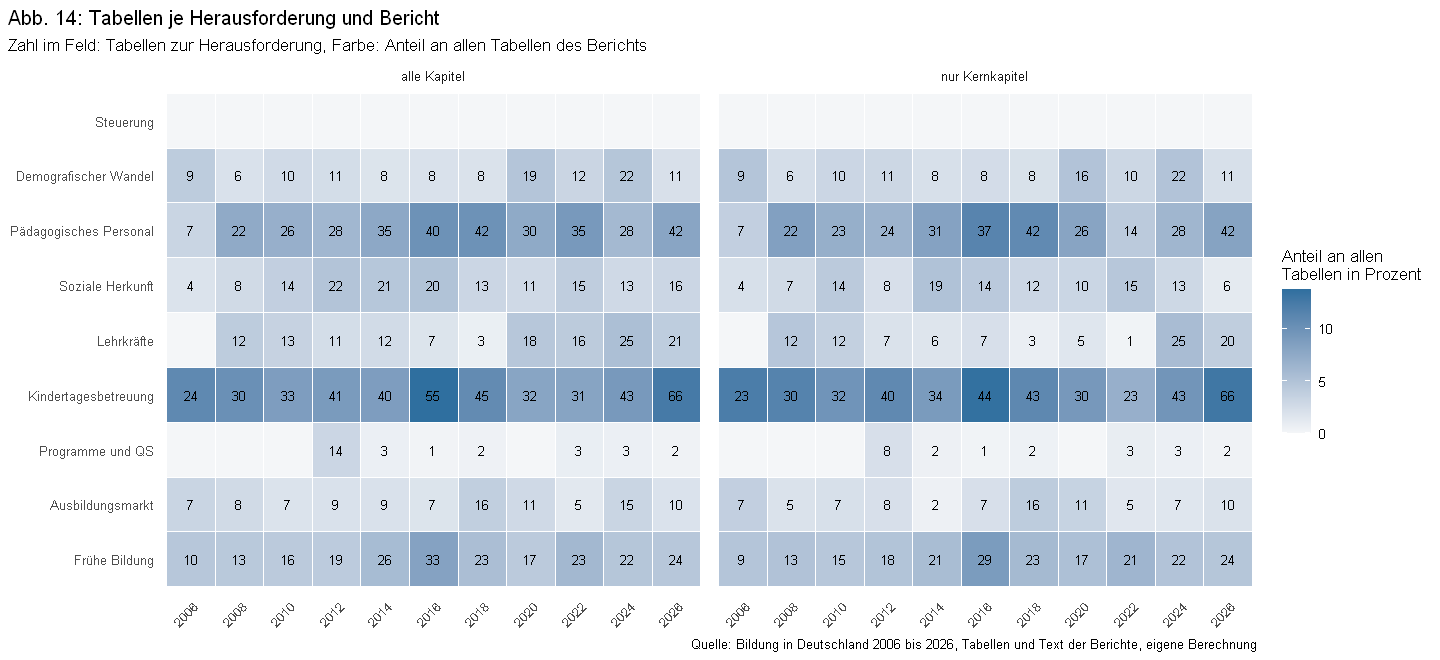

In [11]:
options(repr.plot.width = 12, repr.plot.height = 5.5)

tabellen_jahr <- tabellen |>
  count(jahr, name = "tabellen_bericht")
tabellen_jahr_kern <- tabellen |>
  filter(kapitelgruppe == "Kernkapitel") |>
  count(jahr, name = "tabellen_bericht")

zaehle <- function(daten, gesamt, feld) {
  daten |>
    distinct(thema, kurz, stufe, jahr, pfad, blatt) |>
    count(thema, kurz, stufe, jahr, name = "tabellen") |>
    right_join(crossing(herausforderungen, jahr = jahre), by = c("thema", "kurz", "stufe", "jahr")) |>
    mutate(tabellen = coalesce(tabellen, 0L)) |>
    left_join(gesamt, by = "jahr") |>
    mutate(anteil = 100 * tabellen / tabellen_bericht, feld = feld)
}

abdeckung <- bind_rows(
  zaehle(treffer, tabellen_jahr, "alle Kapitel"),
  zaehle(treffer |> filter(kapitelgruppe == "Kernkapitel"), tabellen_jahr_kern, "nur Kernkapitel")
)
write.csv(abdeckung, "data/processed/indikatoren_abdeckung.csv", row.names = FALSE, fileEncoding = "UTF-8")

abb14 <- ggplot(abdeckung, aes(factor(jahr), factor(kurz, levels = rev(levels(kurz))), fill = anteil)) +
  geom_tile(colour = "white") +
  geom_text(aes(label = if_else(tabellen > 0, as.character(tabellen), "")), size = 2.8) +
  facet_wrap(~ feld) +
  scale_fill_gradient(low = "#f4f6f8", high = "#2f6f9f", name = "Anteil an allen\nTabellen in Prozent") +
  labs(x = NULL, y = NULL,
       title = "Abb. 14: Tabellen je Herausforderung und Bericht",
       subtitle = "Zahl im Feld: Tabellen zur Herausforderung, Farbe: Anteil an allen Tabellen des Berichts",
       caption = quelle) +
  theme_minimal(base_size = 10) +
  theme(panel.grid = element_blank(), plot.title.position = "plot",
        axis.text.x = element_text(angle = 45, hjust = 1))

ggsave("figures/abb14_tabellen_herausforderungen.png", abb14, width = 12, height = 5.5, dpi = 300, bg = "white")

cat("Tabellen je Herausforderung, alle Kapitel:\n")
abdeckung |>
  filter(feld == "alle Kapitel") |>
  select(kurz, jahr, tabellen) |>
  arrange(jahr) |>
  pivot_wider(names_from = jahr, values_from = tabellen) |>
  arrange(kurz) |>
  print(width = Inf)
abb14

**Befund zu Abbildung 14:** Die Tabellen verteilen sich sehr ungleich auf die Herausforderungen.

1. **Steuerung hat keine Tabelle.** In keinem der elf Berichte trägt eine Tabelle einen passenden Titel. Steuerung ist zugleich die Herausforderung mit dem meisten Handlungsbedarf im Text (251 Sätze, Notebook 03).
2. **Programme und Qualitätssicherung hat kaum Tabellen.** 2006 bis 2010 und 2020 gibt es keine, sonst 1 bis 14 Tabellen je Bericht, zusammen 28.
3. **Kindertagesbetreuung hat die meisten Tabellen.** Jeder Bericht enthält 24 bis 66 Tabellen dazu, 2026 so viele wie nie. Das sind 12,5 Prozent aller Tabellen des Berichts 2026.
4. **Pädagogisches Personal wächst.** Von 7 Tabellen (2006) auf 42 (2018 und 2026).
5. **Lehrkräfte schwanken.** 2006 gibt es keine passende Tabelle, 2018 nur 3, 2024 dann 25. In den Kernkapiteln sinkt die Zahl 2022 auf eine einzige Tabelle.
6. **Soziale Herkunft liegt bei 4 bis 22 Tabellen.** 2026 stehen 10 der 16 Tabellen im Schwerpunktkapitel, nur 6 in den Kernkapiteln.

Fast alle Tabellen stehen in den Kernkapiteln. Das Schwerpunktkapitel trägt nur in einzelnen Jahren deutlich bei, etwa bei Programmen und Qualitätssicherung 2012 (6 von 14 Tabellen) und bei sozialer Herkunft 2026.

### 5. Folgen die Tabellen dem Handlungsbedarf im Text?

Hier stelle ich zwei Anteile nebeneinander:

1. **Text:** Anteil der Sätze mit Handlungsbedarf zu einer Herausforderung an allen Sätzen mit Handlungsbedarf des Berichts, aus Notebook 03.
2. **Tabellen:** Anteil der Tabellen zu einer Herausforderung an allen Tabellen des Berichts, aus Abschnitt 4.

Beide Anteile beziehen sich auf den eigenen Bericht. Der wachsende Umfang der Berichte ab 2020 fällt dadurch heraus.

Zusätzlich berechne ich je Herausforderung die Rangkorrelation nach Spearman über die elf Berichte. Ein Wert nahe 1 heißt: In Jahren mit viel Handlungsbedarf im Text gibt es auch viele Tabellen. Ein Wert nahe 0 heißt: Text und Tabellen entwickeln sich unabhängig voneinander. Mit elf Werten ist das eine Beschreibung und kein Test.

Zwei Arten von Lücken zähle ich gesondert:

- **Text ohne Tabelle:** Der Text benennt mindestens 3 Sätze Handlungsbedarf, der Bericht hat aber keine passende Tabelle.
- **Tabelle ohne Text:** Der Bericht hat passende Tabellen, der Text benennt keinen Handlungsbedarf.

#### Abbildung 15: Handlungsbedarf im Text und Anteil der Tabellen

Jedes Feld ist eine Herausforderung. Die rote Linie zeigt den Anteil am Handlungsbedarf im Text, die blaue Linie den Anteil an den Tabellen. Beide Werte sind Prozent des jeweiligen Berichts.

# A tibble: 9 × 7
  kurz                   stufe             saetze_h tabellen text_ohne_tabelle
  <fct>                  <fct>                <dbl>    <int>             <int>
1 Steuerung              belastbar              251        0                11
2 Demografischer Wandel  belastbar              140      124                 0
3 Pädagogisches Personal belastbar              134      335                 0
4 Soziale Herkunft       belastbar               78      157                 0
5 Lehrkräfte             belastbar               56      138                 0
6 Kindertagesbetreuung   mit Einschränkung      150      440                 0
7 Programme und QS       modellabhängig         146       28                 3
8 Ausbildungsmarkt       modellabhängig          98      104                 0
9 Frühe Bildung          modellabhängig          56      226                 0
  tabelle_ohne_text rang_korrelation
              <int>            <dbl>
1                 0            NA   
2 

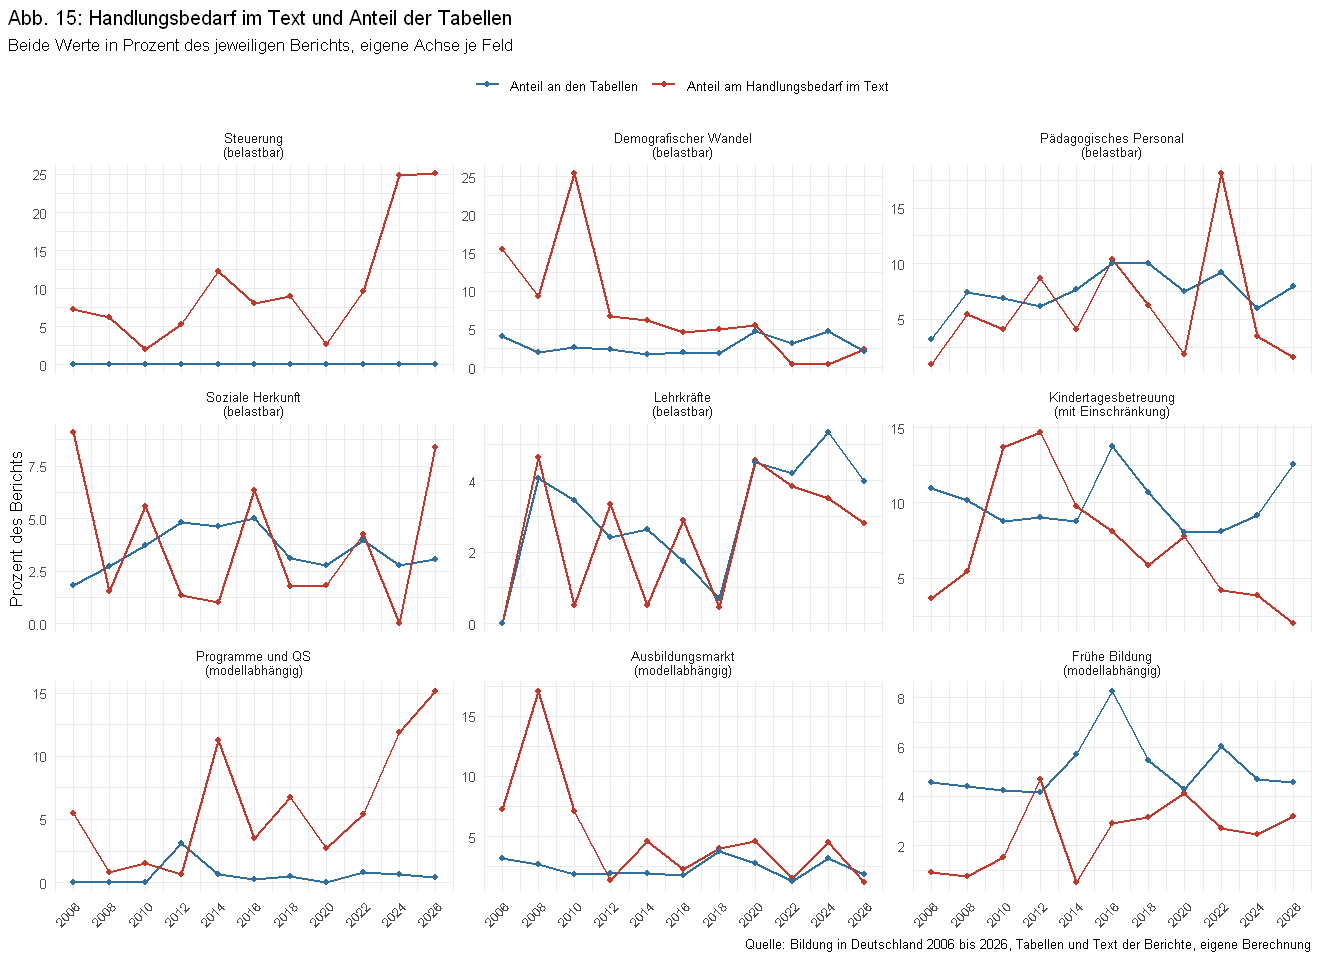

In [12]:
options(repr.plot.width = 11, repr.plot.height = 8)

text_anteil <- h_jahr |>
  group_by(jahr) |>
  mutate(h_bericht = sum(handlungsbedarf)) |>
  ungroup() |>
  filter(thema %in% herausforderungen$thema) |>
  transmute(thema, jahr, saetze_h = handlungsbedarf, anteil_text = 100 * handlungsbedarf / h_bericht)

vergleich <- abdeckung |>
  filter(feld == "alle Kapitel") |>
  select(thema, kurz, stufe, jahr, tabellen, anteil_tabellen = anteil) |>
  left_join(text_anteil, by = c("thema", "jahr")) |>
  mutate(saetze_h = coalesce(as.numeric(saetze_h), 0), anteil_text = coalesce(anteil_text, 0))

spearman <- function(x, y) {
  ok <- !is.na(x) & !is.na(y)
  if (sum(ok) < 3 || sd(x[ok]) == 0 || sd(y[ok]) == 0) return(NA_real_)
  cor(x[ok], y[ok], method = "spearman")
}

zusammenhang <- vergleich |>
  group_by(kurz, stufe) |>
  summarise(text_ohne_tabelle = sum(saetze_h >= 3 & tabellen == 0),
            tabelle_ohne_text = sum(tabellen > 0 & saetze_h == 0),
            rang_korrelation = round(spearman(anteil_text, anteil_tabellen), 2),
            saetze_h = sum(saetze_h),
            tabellen = sum(tabellen),
            .groups = "drop") |>
  relocate(saetze_h, tabellen, .after = stufe)
write.csv(vergleich, "data/processed/indikatoren_text_tabellen.csv", row.names = FALSE, fileEncoding = "UTF-8")
print(zusammenhang, width = Inf)

abb15_daten <- vergleich |>
  select(kurz, stufe, jahr, Text = anteil_text, Tabellen = anteil_tabellen) |>
  pivot_longer(c(Text, Tabellen), names_to = "quelle_wert", values_to = "anteil") |>
  mutate(feld = paste0(kurz, "\n(", stufe, ")"),
         feld = factor(feld, levels = unique(feld[order(kurz)])))

abb15 <- ggplot(abb15_daten, aes(jahr, anteil, colour = quelle_wert)) +
  geom_line(linewidth = 0.8) +
  geom_point(size = 1.4) +
  facet_wrap(~ feld, ncol = 3, scales = "free_y") +
  scale_colour_manual(values = c(Text = "#c0392b", Tabellen = "#2f6f9f"),
                      labels = c(Text = "Anteil am Handlungsbedarf im Text",
                                 Tabellen = "Anteil an den Tabellen"),
                      name = NULL) +
  scale_x_continuous(breaks = jahre) +
  labs(x = NULL, y = "Prozent des Berichts",
       title = "Abb. 15: Handlungsbedarf im Text und Anteil der Tabellen",
       subtitle = "Beide Werte in Prozent des jeweiligen Berichts, eigene Achse je Feld",
       caption = quelle) +
  theme_minimal(base_size = 10) +
  theme(legend.position = "top", plot.title.position = "plot",
        axis.text.x = element_text(angle = 45, hjust = 1))

ggsave("figures/abb15_text_tabellen.png", abb15, width = 11, height = 8, dpi = 300, bg = "white")
abb15

**Befund zu Abbildung 15:** Text und Tabellen folgen bei den meisten Herausforderungen nicht derselben Entwicklung.

| Herausforderung | Rangkorrelation | Muster |
|---|---|---|
| Lehrkräfte | 0,77 | beide steigen ab 2020 |
| Pädagogisches Personal | 0,55 | Text und Tabellen steigen und fallen meist gemeinsam |
| Ausbildungsmarkt | 0,33 | schwacher Zusammenhang |
| Programme und QS | 0,21 | schwacher Zusammenhang auf sehr niedrigem Niveau der Tabellen |
| Demografischer Wandel | -0,08 | kein Zusammenhang |
| Soziale Herkunft | -0,15 | kein Zusammenhang |
| Frühe Bildung | -0,28 | schwach gegenläufig |
| Kindertagesbetreuung | -0,38 | gegenläufig |
| Steuerung | nicht berechenbar | keine Tabellen |

Drei Muster fallen auf:

1. **Text ohne Tabelle.** Steuerung hat in allen 11 Berichten mindestens 3 Sätze Handlungsbedarf, aber nie eine Tabelle. 2024 und 2026 entfällt rund ein Viertel des gesamten Handlungsbedarfs im Text auf Steuerung. Programme und Qualitätssicherung hat in 3 Berichten Handlungsbedarf ohne Tabelle. 2026 entfallen 15 Prozent des Handlungsbedarfs auf dieses Thema, aber nur 0,4 Prozent der Tabellen.
2. **Gegenläufig bei Kindertagesbetreuung.** Der Anteil am Handlungsbedarf im Text erreicht 2010 und 2012 mit 14 bis 15 Prozent seinen Höchstwert, in den Jahren des Krippenausbaus, und fällt bis 2026 auf rund 2 Prozent. Der Anteil an den Tabellen liegt 2026 bei 12,5 Prozent, so hoch wie nie seit 2016. Der Bericht misst das Thema weiter ausführlich, benennt aber immer seltener Handlungsbedarf.
3. **Spitzen im Text ohne Spitzen in den Tabellen.** Demografischer Wandel erreicht 2010 ein Viertel des Handlungsbedarfs, im Jahr des gleichnamigen Schwerpunkts. Der Anteil an den Tabellen bleibt bei 2 bis 5 Prozent. Ähnlich der Ausbildungsmarkt 2008 (17 Prozent im Text, unter 3 Prozent der Tabellen).

Soziale Herkunft ist der einzige Fall von Tabellen ohne Text: 2024 benennt der Text keinen Handlungsbedarf zum Thema, der Bericht enthält aber 13 passende Tabellen.

### 6. Leitindikatoren

Abschnitte 4 und 5 zählen Tabellen. Sie sagen nichts darüber, wie sich die Lage selbst entwickelt. Dafür wähle ich je Herausforderung eine Kennzahl als Leitindikator.

Die Tabellen des neuesten Berichts enthalten meist lange Zeitreihen. Ich suche den Leitindikator deshalb im Bericht 2026. Gibt es dort keine passende Tabelle, nehme ich den neuesten Bericht mit Treffer. Eine Zeitreihe aus einem Bericht hat einen Vorteil: Die Werte sind einheitlich berechnet. Werte aus verschiedenen Berichten kann der Bericht später korrigiert haben, die Seiten "Daten" weisen ausdrücklich darauf hin.

Das Vorgehen je Tabelle:

1. Ich suche eine Zeile mit mindestens vier Jahreszahlen, etwa 2006, 2010 und 2024. Das ist die Kopfzeile der Zeitreihe.
2. Unter dieser Zeile suche ich die erste Zeile, die links von den Jahreszahlen mit "Deutschland", "Insgesamt" oder "Zusammen" beschriftet ist. Ihre Werte unter den Jahreszahlen bilden die Zeitreihe.
3. Stehen die Jahre untereinander statt nebeneinander, wiederhole ich die Suche mit der gedrehten Tabelle.

4. Werte ab dem Berichtsjahr lasse ich weg. Das sind Vorausberechnungen, etwa zum Lehrkräftebedarf bis 2035, und keine beobachtete Entwicklung. Bleiben weniger als vier Werte, fällt die Tabelle weg.

Von allen Tabellen einer Herausforderung, in denen das gelingt, wähle ich die mit den meisten Jahren. Alle gefundenen Zeitreihen mit Titel schreibe ich nach `data/interim/indikator_kandidaten.xlsx`.

Diese automatische Auswahl ist ein Vorschlag. Sie weiß nicht, ob eine Kennzahl inhaltlich die beste ist oder ob die Zeile "Insgesamt" eine Anzahl oder eine Quote enthält. Nach dem ersten Lauf habe ich die Kandidaten geprüft. Bei Kindertagesbetreuung wählte die Automatik die Zahl der Kindertagespflegepersonen. Ich lege stattdessen die Zahl der Kindertageseinrichtungen fest (Tabelle C2-1web), weil sie den Ausbau der Einrichtungen abbildet. Bei Lehrkräften wählte die Automatik im ersten Lauf eine Vorausberechnung bis 2035. Durch Schritt 4 fällt sie weg. Für alle anderen Herausforderungen gilt die automatische Auswahl.

In [13]:
ist_jahr <- function(x) !is.na(x) & grepl("^(19[5-9]\\d|20[0-4]\\d)(/\\d{2,4})?[^0-9]{0,2}$", x)

suche_reihe <- function(m) {
  jahr_matrix <- matrix(ist_jahr(m), nrow(m))
  kopf <- which(rowSums(jahr_matrix) >= 4)[1]
  if (is.na(kopf)) return(NULL)
  spalten <- which(jahr_matrix[kopf, ])
  erste <- apply(m, 1, function(z) {
    z <- z[!is.na(z) & z != ""]
    if (length(z)) z[1] else NA_character_
  })
  vor_jahren <- seq_len(min(spalten) - 1)
  ist_summe <- apply(m[, vor_jahren, drop = FALSE], 1, function(z)
    any(grepl("^(deutschland|insgesamt|zusammen)", tolower(z[!is.na(z)]))))
  zeile <- which(seq_len(nrow(m)) > kopf & ist_summe)[1]
  if (is.na(zeile)) return(NULL)
  erste[zeile] <- str_subset(m[zeile, vor_jahren], "(?i)^(deutschland|insgesamt|zusammen)")[1]
  werte <- suppressWarnings(as.numeric(gsub(",", ".", m[zeile, spalten])))
  reihe <- tibble(zeitpunkt = m[kopf, spalten],
                  jahr_wert = as.integer(substr(m[kopf, spalten], 1, 4)),
                  wert = werte,
                  zeile = erste[zeile]) |>
    filter(!is.na(wert)) |>
    distinct(jahr_wert, .keep_all = TRUE)
  if (nrow(reihe) < 4) NULL else reihe
}

lies_reihe <- function(pfad, blatt) {
  d <- tryCatch(suppressMessages(readxl::read_excel(pfad, sheet = blatt, col_names = FALSE,
                                                     col_types = "text", .name_repair = "minimal")),
                error = function(e) NULL)
  if (is.null(d) || nrow(d) == 0) return(NULL)
  m <- trimws(as.matrix(d))
  reihe <- suche_reihe(m)
  if (is.null(reihe)) reihe <- suche_reihe(t(m))
  reihe
}

neuester <- treffer |>
  group_by(thema) |>
  filter(jahr == max(jahr)) |>
  ungroup() |>
  distinct(thema, kurz, stufe, jahr, tab_nr, pfad, blatt, titel)

kandidaten <- neuester |>
  mutate(reihe = map2(pfad, blatt, lies_reihe),
         reihe = map2(reihe, jahr, function(r, j) {
           if (is.null(r)) return(NULL)
           r <- filter(r, jahr_wert < j)
           if (nrow(r) < 4) NULL else r
         })) |>
  filter(!map_lgl(reihe, is.null)) |>
  mutate(jahre_reihe = map_int(reihe, nrow),
         von = map_int(reihe, \(r) min(r$jahr_wert)),
         bis = map_int(reihe, \(r) max(r$jahr_wert)),
         zeile = map_chr(reihe, \(r) r$zeile[1]))

writexl::write_xlsx(kandidaten |> select(kurz, jahr, tab_nr, blatt, titel, zeile, jahre_reihe, von, bis),
                    "data/interim/indikator_kandidaten.xlsx")

cat("Tabellen im neuesten Bericht je Herausforderung und davon lesbare Zeitreihen:\n")
neuester |>
  count(kurz, jahr, name = "tabellen") |>
  left_join(kandidaten |> count(kurz, name = "zeitreihen"), by = "kurz") |>
  mutate(zeitreihen = coalesce(zeitreihen, 0L)) |>
  print(n = Inf)

Tabellen im neuesten Bericht je Herausforderung und davon lesbare Zeitreihen:
# A tibble: 8 × 4
  kurz                    jahr tabellen zeitreihen
  <fct>                  <int>    <int>      <int>
1 Demografischer Wandel   2026       11          5
2 Pädagogisches Personal  2026       42          3
3 Soziale Herkunft        2026       16          0
4 Lehrkräfte              2026       21          2
5 Kindertagesbetreuung    2026       66          7
6 Programme und QS        2026        2          0
7 Ausbildungsmarkt        2026       10          3
8 Frühe Bildung           2026       24          6


Die nächste Zelle legt den Leitindikator je Herausforderung fest. In `auswahl_fest` steht für eine Herausforderung eine bestimmte Tabelle, hier für Kindertagesbetreuung die Tabelle C2-1web. Für alle anderen gilt die Tabelle mit der längsten Zeitreihe.

#### Abbildung 16: Leitindikatoren

Jedes Feld zeigt die Zeitreihe des Leitindikators einer Herausforderung, aus dem neuesten Bericht mit passender Tabelle. Über dem Feld stehen Tabellennummer und Bericht. Die Einheit, etwa Anzahl oder Prozent, steht im Titel der Tabelle in `data/interim/indikator_kandidaten.xlsx`. Die senkrechten roten Linien markieren die Berichtsjahre, in denen der Text mindestens 3 Sätze Handlungsbedarf zu dieser Herausforderung enthält und ihr Anteil am Handlungsbedarf des Berichts über dem Durchschnitt aller Themen liegt.

Herausforderungen ohne lesbaren Leitindikator: Steuerung, Soziale Herkunft, Programme und QS 

# A tibble: 6 × 8
  kurz                   stufe              jahr tab_nr  
  <fct>                  <fct>             <int> <chr>   
1 Demografischer Wandel  belastbar          2026 A1-1web 
2 Pädagogisches Personal belastbar          2026 C3-1web 
3 Lehrkräfte             belastbar          2026 D4-5web 
4 Kindertagesbetreuung   mit Einschränkung  2026 C2-1web 
5 Ausbildungsmarkt       modellabhängig     2026 E1-4web 
6 Frühe Bildung          modellabhängig     2026 C5-10web
  zeile                             jahre_reihe   von   bis
  <chr>                                   <int> <int> <int>
1 Zusammengefasste Geburtenziffer1)          34  1991  2024
2 Deutschland                                20  2006  2025
3 Insgesamt                                  11  2014  2024
4 Deutschland                                13  2006  2024
5 Insgesamt                                  21  2005  2025
6 D

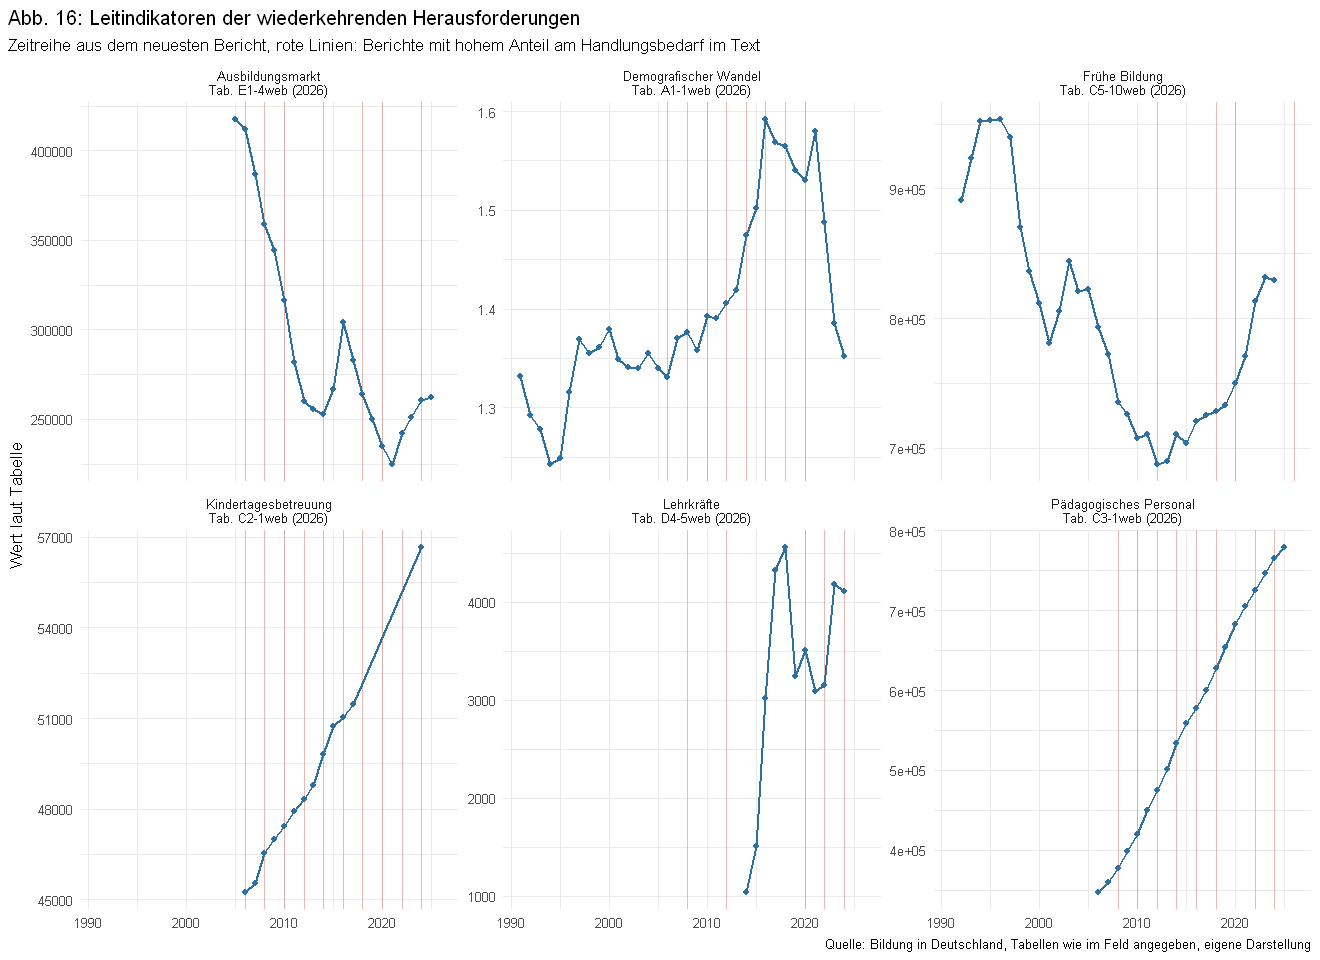

In [14]:
options(repr.plot.width = 11, repr.plot.height = 8)

auswahl_fest <- tibble(kurz = "Kindertagesbetreuung", tab_nr = "C2-1web")

fehlt_fest <- setdiff(paste(auswahl_fest$kurz, auswahl_fest$tab_nr), paste(kandidaten$kurz, kandidaten$tab_nr))
if (length(fehlt_fest)) cat("Festgelegt, aber nicht unter den Kandidaten:", paste(fehlt_fest, collapse = "; "), "\n")

leit <- kandidaten |>
  mutate(fest = paste(kurz, tab_nr) %in% paste(auswahl_fest$kurz, auswahl_fest$tab_nr),
         hat_fest = as.character(kurz) %in% auswahl_fest$kurz) |>
  filter(!hat_fest | fest) |>
  group_by(kurz) |>
  arrange(desc(jahre_reihe), tab_nr, .by_group = TRUE) |>
  slice_head(n = 1) |>
  ungroup()

ohne_leit <- setdiff(as.character(herausforderungen$kurz), as.character(leit$kurz))
cat("Herausforderungen ohne lesbaren Leitindikator:",
    if (length(ohne_leit)) paste(ohne_leit, collapse = ", ") else "keine", "\n\n")
print(leit |> select(kurz, stufe, jahr, tab_nr, zeile, jahre_reihe, von, bis), width = Inf)

leit_reihen <- leit |>
  select(thema, kurz, stufe, jahr, tab_nr, reihe) |>
  unnest(reihe) |>
  mutate(feld = paste0(kurz, "\nTab. ", tab_nr, " (", jahr, ")"))
write.csv(leit_reihen |> select(kurz, stufe, bericht = jahr, tab_nr, zeitpunkt, jahr_wert, wert),
          "data/processed/leitindikatoren.csv", row.names = FALSE, fileEncoding = "UTF-8")

markierung <- vergleich |>
  filter(saetze_h >= 3, anteil_text > 100 / n_distinct(h_jahr$thema)) |>
  select(kurz, jahr_markiert = jahr) |>
  inner_join(leit_reihen |> distinct(kurz, feld), by = "kurz")

abb16 <- ggplot(leit_reihen, aes(jahr_wert, wert)) +
  geom_vline(data = markierung, aes(xintercept = jahr_markiert), colour = "#c0392b", alpha = 0.35) +
  geom_line(colour = "#2f6f9f", linewidth = 0.8) +
  geom_point(colour = "#2f6f9f", size = 1.3) +
  facet_wrap(~ feld, ncol = 3, scales = "free_y") +
  labs(x = NULL, y = "Wert laut Tabelle",
       title = "Abb. 16: Leitindikatoren der wiederkehrenden Herausforderungen",
       subtitle = "Zeitreihe aus dem neuesten Bericht, rote Linien: Berichte mit hohem Anteil am Handlungsbedarf im Text",
       caption = "Quelle: Bildung in Deutschland, Tabellen wie im Feld angegeben, eigene Darstellung") +
  theme_minimal(base_size = 10) +
  theme(plot.title.position = "plot")

ggsave("figures/abb16_leitindikatoren.png", abb16, width = 11, height = 8, dpi = 300, bg = "white")
abb16

**Befund zu Abbildung 16:** Für sechs der neun Herausforderungen findet die Regel eine Zeitreihe. Für Steuerung und Programme und Qualitätssicherung gibt es im Bericht 2026 keine lesbare Tabelle mit Zeitreihe. Für soziale Herkunft gibt es 16 passende Tabellen, aber keine mit einer Zeile "Deutschland" oder "Insgesamt" über mindestens vier Jahre. Das heißt nicht, dass es keine Zeitreihe gibt. Die Tabellen gliedern meist nach Gruppen, etwa nach Risikolage oder Status, und nicht nach Jahren.

| Herausforderung | Tabelle 2026 | Kennzahl laut Tabellentitel | Entwicklung |
|---|---|---|---|
| Demografischer Wandel | A1-1web | zusammengefasste Geburtenziffer | 1,24 Kinder je Frau (1994), Höchstwert 1,59 (2016), 1,35 (2024) |
| Pädagogisches Personal | C3-1web | pädagogisches Personal in Kindertageseinrichtungen, Zeile Deutschland | von rund 350.000 (2006) auf rund 780.000 (2025), mehr als verdoppelt |
| Lehrkräfte | D4-5web | Neueinstellungen ohne Lehramtsprüfung, Zeile Insgesamt | von rund 1.000 (Schuljahr 2014/15) auf rund 4.600 (2018/19), danach 3.100 bis 4.200 |
| Kindertagesbetreuung | C2-1web | Kindertageseinrichtungen ohne Horte | von rund 45.300 (2006) auf rund 56.700 (2024) |
| Ausbildungsmarkt | E1-4web | Neuzugänge in den Übergangssektor | von rund 417.000 (2005) auf rund 225.000 (2021), danach Anstieg auf rund 262.000 (2025) |
| Frühe Bildung | C5-10web | Einschulungen | Höchstwert rund 955.000 (1996), Tiefstwert rund 687.000 (2012), rund 833.000 (2023) |

Die Werte habe ich aus der Abbildung abgelesen und gerundet. Die genauen Werte stehen in `data/processed/leitindikatoren.csv`.

Drei Beobachtungen:

1. **Handlungsbedarf und Indikator laufen bei Kindertagesbetreuung auseinander.** Die Zahl der Einrichtungen und das Personal wachsen ohne Unterbrechung. Der Handlungsbedarf im Text erreicht 2010 und 2012 seinen Höchstwert und geht danach zurück. Das passt zu einem Ausbau, den der Bericht zuerst fordert und dann als Kennzahl fortschreibt.
2. **Lehrkräfte: Der Indikator zeigt den Mangel früher als der Text.** Die Neueinstellungen ohne Lehramtsprüfung vervierfachen sich zwischen 2014/15 und 2018/19. Im Text liegt der Handlungsbedarf zu Lehrkräften erst ab 2020 dauerhaft höher, bei 7 bis 10 Sätzen je Bericht (Notebook 03, Abbildung 10).
3. **Ausbildungsmarkt und Demografie zeigen Wendepunkte.** Die Neuzugänge in den Übergangssektor steigen 2016 kurz an und erneut ab 2022. Die Geburtenziffer fällt seit 2021 deutlich. Beide Wendepunkte liegen in Jahren mit wenig Handlungsbedarf im Text zum jeweiligen Thema.

Einschränkungen: Die Kindertageseinrichtungen haben zwischen 2017 und 2024 keine Werte in der Tabelle, die Linie verbindet die beiden Jahre direkt. Die Einschulungen sind eher eine demografische Kennzahl als ein Maß für frühe Bildung. Bei pädagogischem Personal weiß ich nicht sicher, ob die Zeile Deutschland die Kindertagespflegepersonen mitzählt.

## Zusammenfassung

### Ziel

Dieses Notebook beantwortet den zweiten Teil von Forschungsfrage 2. Es verbindet die wiederkehrenden Herausforderungen aus dem Text mit den Tabellen der Berichte.

### Entscheidungen und Gründe

| Schritt | Entscheidung | Grund |
|---|---|---|
| Daten | bereinigter Bestand aus `04_tabellenbestand.ipynb`, nur Tabellen | Die Tabellen sind die Indikatoren des Berichts. Abbildungsdaten liegen nicht für alle Jahre gleich vor |
| Einheit | Tabelle, erkannt am Blatt der Excel-Datei | Eine Tabelle ist die kleinste Einheit mit eigenem Titel |
| Zuordnung | Wortteile im Tabellentitel, Mehrfachzuordnung erlaubt, nach Prüfung der Treffer korrigiert | einfach, nachvollziehbar, für jede Tabelle überprüfbar |
| Vergleich | Anteile am eigenen Bericht für Text und Tabellen | Der wachsende Umfang der Berichte fällt heraus |
| Zusammenhang | Rangkorrelation nach Spearman über elf Berichte, beschreibend | Mit elf Werten ist ein Test nicht sinnvoll |
| Leitindikator | längste Zeitreihe aus dem Bericht 2026 ohne Vorausberechnungen, Zeile "Deutschland" oder "Insgesamt", bei Kindertagesbetreuung festgelegt | einheitlich berechnete Werte, Korrekturen späterer Berichte sind berücksichtigt |

### Zentrale Befunde

1. **Die stärkste Herausforderung im Text hat keine Tabelle.** Steuerung benennt der Bericht in allen elf Ausgaben wiederholt als Handlungsbedarf, 2024 und 2026 entfällt rund ein Viertel des Handlungsbedarfs darauf. Keine einzige Tabelle trägt einen passenden Titel. Programme und Qualitätssicherung zeigen dasselbe Muster in schwächerer Form.
2. **Text und Tabellen entwickeln sich meist unabhängig.** Nur bei Lehrkräften (0,77) und pädagogischem Personal (0,55) steigen und fallen beide gemeinsam. Bei Kindertagesbetreuung laufen sie gegeneinander (-0,38): viele Tabellen, immer weniger Handlungsbedarf.
3. **Spitzen im Text stammen aus Schwerpunkten, nicht aus den Tabellen.** Demografischer Wandel 2010 und Ausbildungsmarkt 2008 erreichen hohe Anteile am Handlungsbedarf, ohne dass der Anteil der Tabellen steigt.
4. **Die Leitindikatoren zeigen klare Entwicklungen.** Personal in Kindertageseinrichtungen mehr als verdoppelt, Einrichtungen um rund ein Viertel gewachsen, Neueinstellungen ohne Lehramtsprüfung bis 2018/19 vervierfacht, Neuzugänge in den Übergangssektor seit 2005 um mehr als ein Drittel gesunken, Geburtenziffer seit 2021 deutlich gefallen.
5. **Bei Lehrkräften zeigt der Indikator den Mangel früher als der Text.** Die Neueinstellungen ohne Lehramtsprüfung steigen ab 2015, der Handlungsbedarf im Text liegt erst ab 2020 dauerhaft höher.

### Grenzen

- Die Zuordnung über Titel erkennt keine Bedeutung. Nach der Korrektur sind einzelne Tabellen weiter falsch oder gar nicht zugeordnet, vor allem bei pädagogischem Personal. Die Datei `data/interim/tabellen_herausforderungen.xlsx` erlaubt die Prüfung.
- Die Zahl der Tabellen misst, wie viel Raum der Bericht einer Herausforderung gibt, nicht wie gut er sie misst.
- Die Werte in den Befunden zu Abbildung 16 sind aus der Abbildung abgelesen und gerundet.
- Der Leitindikator ist eine Kennzahl unter vielen. Er zeigt eine Richtung, nicht die ganze Lage. Für soziale Herkunft, Steuerung sowie Programme und Qualitätssicherung findet die Regel keinen.
- Der Handlungsbedarf im Text stammt aus dem Wörterbuch in Notebook 03. Die Handcodierung zu seiner Prüfung ist nicht durchgeführt.